# 🦠 COVID-19 Data Analysis & Prediction Project


1. Load Dataset
       ↓
2. Understand Dataset
       ↓
3. Data Cleaning
       ↓
4. Feature Engineering
       ↓
5. Exploratory Data Analysis (EDA)
       ↓
6. Data Visualization
       ↓
7. Statistical Analysis
       ↓
8. Machine Learning
       ↓
9. Model Evaluation
       ↓
10. Final Insights

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(r"C:\Users\navee\Desktop\python libraries\Projects series\csv data sets\4. Covid_19_data (1).csv")
df

,Date,State,Region,Confirmed,Deaths,Recovered
0,4/29/2020,NaN,Afghanistan,1939,60,252
1,4/29/2020,NaN,Albania,766,30,455
2,4/29/2020,NaN,Algeria,3848,444,1702
3,4/29/2020,NaN,Andorra,743,42,423
4,4/29/2020,NaN,Angola,27,2,7
...,...,...,...,...,...,...
316,4/29/2020,Wyoming,US,545,7,0
317,4/29/2020,Xinjiang,Mainland China,76,3,73
318,4/29/2020,Yukon,Canada,11,0,0
319,4/29/2020,Yunnan,Mainland China,185,2,181


## 🧠 Understand the data 

In [3]:
df.shape

(321, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 321 entries, 0 to 320
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Date       321 non-null    object
 1   State      140 non-null    object
 2   Region     321 non-null    object
 3   Confirmed  321 non-null    int64 
 4   Deaths     321 non-null    int64 
 5   Recovered  321 non-null    int64 
dtypes: int64(3), object(3)
memory usage: 15.2+ KB


In [5]:
df.describe()

,Confirmed,Deaths,Recovered
count,321.000000,321.000000,321.000000
mean,9949.800623,709.152648,3030.277259
std,31923.853086,3236.162817,14364.870365
min,0.000000,0.000000,0.000000
25%,104.000000,2.000000,2.000000
50%,653.000000,12.000000,73.000000
75%,4655.000000,144.000000,587.000000
max,299691.000000,27682.000000,132929.000000


In [6]:
df.dtypes

Date         object
State        object
Region       object
Confirmed     int64
Deaths        int64
Recovered     int64
dtype: object

In [7]:
df.isnull().sum()

Date           0
State        181
Region         0
Confirmed      0
Deaths         0
Recovered      0
dtype: int64

## 🧹 Data Cleaning

In [8]:
df.drop(columns=['State'], inplace = True)

In [9]:
df.isnull().sum()

Date         0
Region       0
Confirmed    0
Deaths       0
Recovered    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 321 entries, 0 to 320
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Date       321 non-null    object
 1   Region     321 non-null    object
 2   Confirmed  321 non-null    int64 
 3   Deaths     321 non-null    int64 
 4   Recovered  321 non-null    int64 
dtypes: int64(3), object(2)
memory usage: 12.7+ KB


In [12]:
# here date is object so we have to covert into date formate
df['Date'] = pd.to_datetime(df['Date'])

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 321 entries, 0 to 320
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       321 non-null    datetime64[ns]
 1   Region     321 non-null    object        
 2   Confirmed  321 non-null    int64         
 3   Deaths     321 non-null    int64         
 4   Recovered  321 non-null    int64         
dtypes: datetime64[ns](1), int64(3), object(1)
memory usage: 12.7+ KB


## Feature Engineering

In [14]:
# create year, month , day, day_name columns from DATE column 
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['Day_Name'] = df['Date'].dt.day_name()

In [15]:
# Now create the columns recovery rate and death rate 
df['Recovery_Rate'] = (
    df['Recovered']/df['Confirmed']
)*100

In [16]:
df['Death_Rate'] = (
    df['Deaths'] / df['Confirmed']
)*100    

In [17]:
df.head()

,Date,Region,Confirmed,Deaths,Recovered,Year,Month,Day,Day_Name,Recovery_Rate,Death_Rate
0,2020-04-29,Afghanistan,1939,60,252,2020,4,29,Wednesday,12.996390,3.094379
1,2020-04-29,Albania,766,30,455,2020,4,29,Wednesday,59.399478,3.916449
2,2020-04-29,Algeria,3848,444,1702,2020,4,29,Wednesday,44.230769,11.538462
3,2020-04-29,Andorra,743,42,423,2020,4,29,Wednesday,56.931359,5.652759
4,2020-04-29,Angola,27,2,7,2020,4,29,Wednesday,25.925926,7.407407


_____________

## 🔎 EDA

- Find Total confirmed cases, Total deaths and total Recovered 

In [18]:
print(f'Total Confirmed cases: {df['Confirmed'].sum()}')
print(f'Total Deaths: {df['Deaths'].sum()}')
print(f'Total Recovered: {df['Recovered'].sum()}')

Total Confirmed cases: 3193886
Total Deaths: 227638
Total Recovered: 972719


- Average confirmed cases?

In [19]:
print(f'Average Confirmed cases: {df['Confirmed'].mean().round(2)}')

Average Confirmed cases: 9949.8


- Maximum and min confirmed cases in  record?

In [20]:
print(f'Max confirmed cases: {df['Confirmed'].max()}')
print(f'Min confirmed cases: {df['Confirmed'].min()}')

Max confirmed cases: 299691
Min confirmed cases: 0


- Total confirmed cases by Region

In [21]:
country_case = df.groupby('Region')['Confirmed'].sum().sort_values(ascending=False).head(10)
country_case

Region
US                1039909
Spain              236899
Italy              203591
France             166543
UK                 166441
Germany            161539
Turkey             117589
Russia              99399
Iran                93657
Mainland China      82862
Name: Confirmed, dtype: int64

- Total confirmed cases by Region

In [22]:
country_death = df.groupby('Region')['Deaths'].sum().sort_values(ascending=False).head(10)
country_death

Region
US             60967
Italy          27682
UK             26166
Spain          24275
France         24121
Belgium         7501
Germany         6467
Iran            5957
Brazil          5513
Netherlands     4727
Name: Deaths, dtype: int64

- Total Recovered cases by Region

In [23]:
country_rec = df.groupby('Region')['Recovered'].sum().sort_values(ascending=False)
country_rec.head(10)

Region
Spain             132929
US                120720
Germany           120400
Mainland China     77610
Iran               73791
Italy              71252
France             49118
Turkey             44040
Brazil             34132
Switzerland        22600
Name: Recovered, dtype: int64

## 📊 Visualization

- Top 10 countries by Confirmed Cases

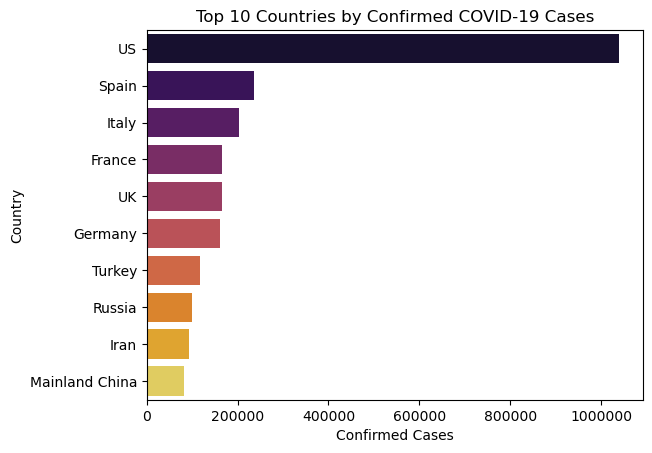

In [24]:
sns.barplot(x = country_case.values, y = country_case.index, palette='inferno')
plt.title('Top 10 Countries by Confirmed COVID-19 Cases')
plt.xlabel('Confirmed Cases')
plt.ylabel('Country')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

- Top 10 Countries by Deaths

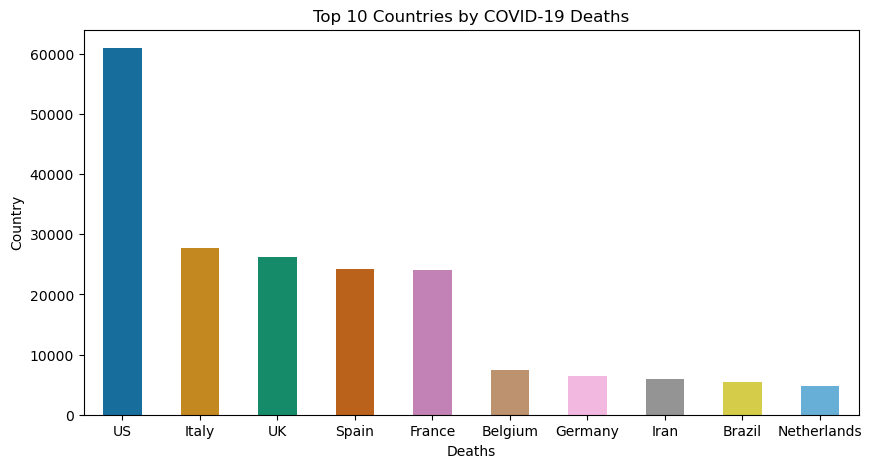

In [25]:
top10_deaths = df.groupby('Region')['Deaths'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
sns.barplot(
    y=top10_deaths.values,
    x=top10_deaths.index,
    palette='colorblind',
    width = 0.5
)
plt.title('Top 10 Countries by COVID-19 Deaths')
plt.xlabel('Deaths')
plt.ylabel('Country')
plt.show()

- Confirmed vs Deaths

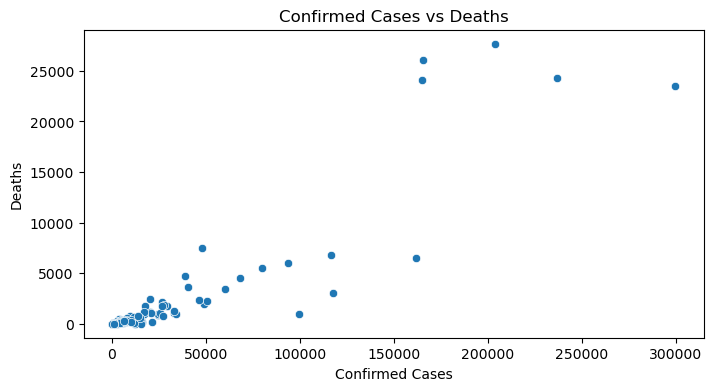

In [26]:
plt.figure(figsize=(8,4))
sns.scatterplot(
    data=df,
    x='Confirmed',
    y='Deaths',
)
plt.title('Confirmed Cases vs Deaths')
plt.xlabel('Confirmed Cases')
plt.ylabel('Deaths')
plt.show()

- Confirmed vs Recovered

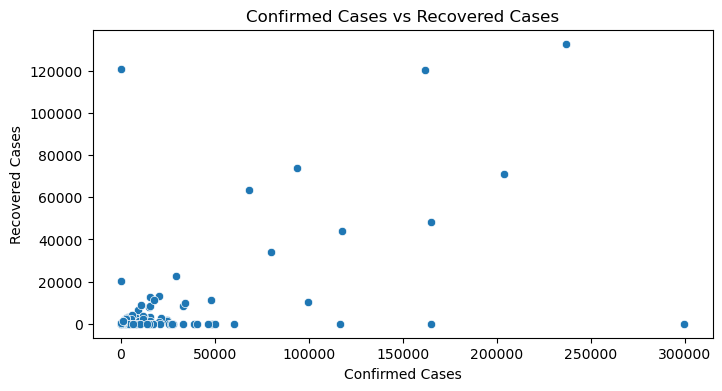

In [27]:
plt.figure(figsize=(8,4))
sns.scatterplot(
    data=df,
    x='Confirmed',
    y='Recovered'
)
plt.title('Confirmed Cases vs Recovered Cases')
plt.xlabel('Confirmed Cases')
plt.ylabel('Recovered Cases')
plt.show()

- Correlation Heatmap

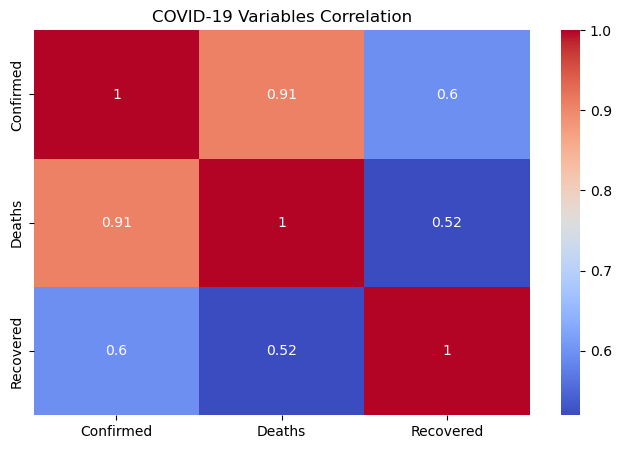

In [28]:
numeric_cols = [
    'Confirmed',
    'Deaths',
    'Recovered'
]
plt.figure(figsize=(8,5))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title('COVID-19 Variables Correlation')
plt.show()

- Distribution

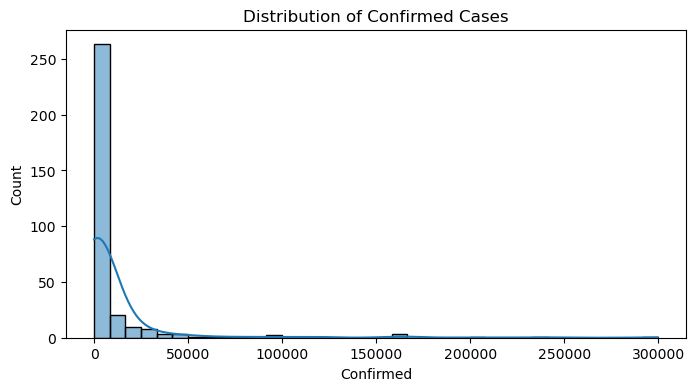

In [29]:
plt.figure(figsize=(8,4))
sns.histplot(
    df['Confirmed'],
    kde=True
)
plt.title('Distribution of Confirmed Cases')
plt.show()

- Boxplot — Outliers

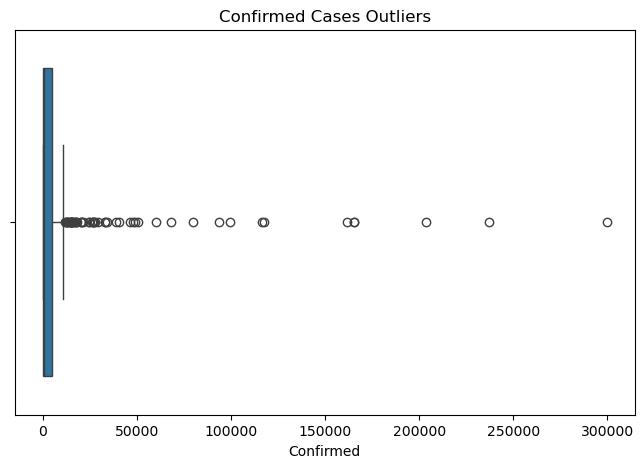

In [30]:
plt.figure(figsize=(8,5))
sns.boxplot(
    x=df['Confirmed']
)
plt.title('Confirmed Cases Outliers')
plt.show()

# 🤖 ML part 
## Predicting Deaths from Confirmed & Recovered Cases

Training Data: (256, 2)
Testing Data: (65, 2)

----- Linear Regression -----
MAE: 463.6919957125015
MSE: 1722884.4374724976
RMSE: 1312.586925682447
R2 Score: 0.8229063822196718

----- Random Forest Regression -----
MAE: 179.94292307692305
MSE: 371474.1794446154
RMSE: 609.4868164649794
R2 Score: 0.9618165299314361

----- Model Comparison -----


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,463.691996,1.722884e+06,1312.586926,0.822906
1,Random Forest,179.942923,3.714742e+05,609.486816,0.961817


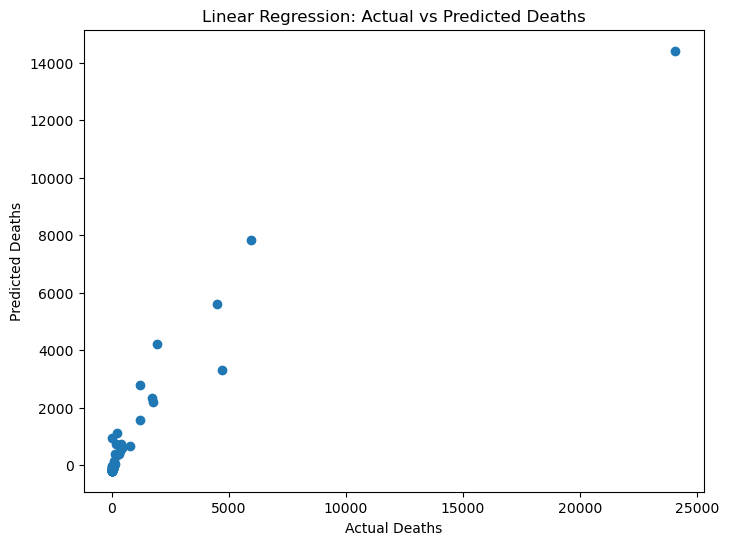

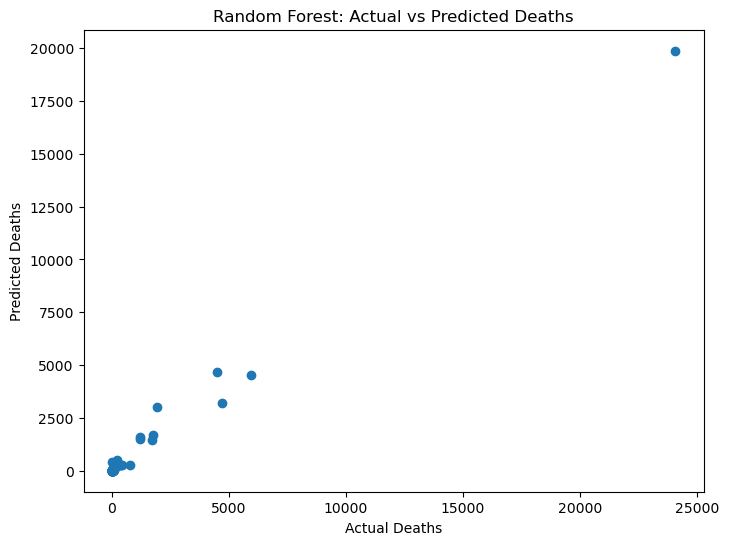


----- Feature Importance -----


,Feature,Importance
0,Confirmed,0.967034
1,Recovered,0.032966


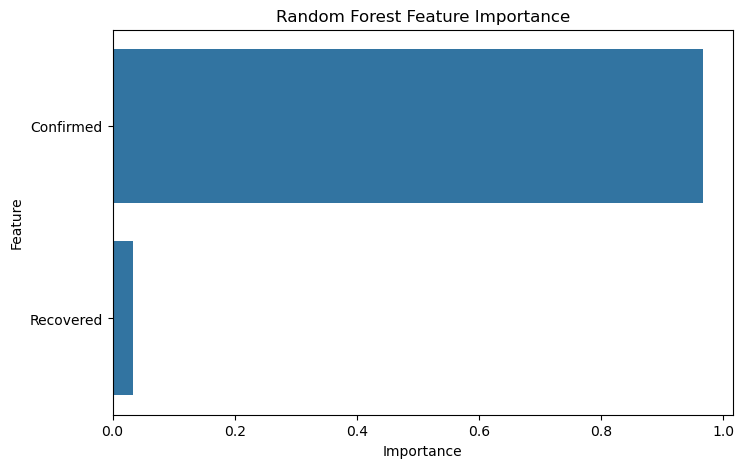


----- Actual vs Predicted -----


,Actual Deaths,Linear Regression,Random Forest
0,9,-16.742604,53.44
1,10,933.953864,395.77
2,38,-144.784680,6.66
3,23,-38.951662,31.75
4,4,-151.190579,7.00
5,32,-129.200874,9.88
6,4,-150.884135,15.86
7,1716,2332.879082,1474.82
8,13,-109.683822,7.53
9,4,-185.886543,0.82


In [31]:
# ==========================================
# COVID-19 ML PROJECT
# Predicting Deaths from Confirmed & Recovered Cases
# ==========================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ==========================================
# 2. Select Features and Target
# ==========================================

X = df[['Confirmed', 'Recovered']]
y = df['Deaths']


# ==========================================
# 3. Train-Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# ==========================================
# 4. Linear Regression
# ==========================================

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)


# ==========================================
# 5. Linear Regression Evaluation
# ==========================================

lr_mae = mean_absolute_error(y_test, lr_pred)
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_pred)

print("\n----- Linear Regression -----")
print("MAE:", lr_mae)
print("MSE:", lr_mse)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)


# ==========================================
# 6. Random Forest Regression
# ==========================================

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)


# ==========================================
# 7. Random Forest Evaluation
# ==========================================

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("\n----- Random Forest Regression -----")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)


# ==========================================
# 8. Model Comparison
# ==========================================

results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [lr_mae, rf_mae],
    'MSE': [lr_mse, rf_mse],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

print("\n----- Model Comparison -----")
display(results)


# ==========================================
# 9. Actual vs Predicted - Linear Regression
# ==========================================

plt.figure(figsize=(8, 6))

plt.scatter(y_test, lr_pred)

plt.xlabel('Actual Deaths')
plt.ylabel('Predicted Deaths')
plt.title('Linear Regression: Actual vs Predicted Deaths')

plt.show()


# ==========================================
# 10. Actual vs Predicted - Random Forest
# ==========================================

plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred)

plt.xlabel('Actual Deaths')
plt.ylabel('Predicted Deaths')
plt.title('Random Forest: Actual vs Predicted Deaths')

plt.show()


# ==========================================
# 11. Feature Importance
# ==========================================

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

print("\n----- Feature Importance -----")
display(feature_importance)


# ==========================================
# 12. Feature Importance Visualization
# ==========================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()


# ==========================================
# 13. Actual vs Predicted Table
# ==========================================

comparison = pd.DataFrame({
    'Actual Deaths': y_test.values,
    'Linear Regression': lr_pred,
    'Random Forest': rf_pred
})

print("\n----- Actual vs Predicted -----")
display(comparison.head(10))